In [7]:
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import trange
from scipy.optimize import minimize
from scipy.linalg import orth
from tqdm import trange
import helpers_attractors as h
import importlib
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.interpolate import CubicSpline, RectBivariateSpline
from matplotlib.path import Path

device = "cuda" if torch.cuda.is_available() else "cpu"

In [8]:
mu = np.array([
    [1,2],
    [-1.5,0],
    [1,-2.25]
]).T

sigma = 0.75*np.ones(mu.shape[1])
A = 0.25*np.ones(mu.shape[1])

(u_x,u_y), r = h.intersecting_circle(mu)

c = [u_x, u_y]

theta = 1

M = np.array([
    [0,theta],
    [-theta,0]
])

xi = 0.6
nu = 0.2
alpha = 1.5 #

mu_np = mu.T.copy() 
mu_t = torch.from_numpy(mu_np).to(device=device, dtype=torch.float32)   # (K,2)
A_t = torch.from_numpy(A.astype(np.float32)).to(device=device)          # (K,)
sigma_t = torch.from_numpy(sigma.astype(np.float32)).to(device=device)  # (K,)

c_t = torch.tensor([u_x, u_y], device=device, dtype=torch.float32)   # (2,)
r_t = float(r)
xi_t = float(xi)
M_t = torch.from_numpy(M.astype(np.float32)).to(device=device)       # (2,2)
alpha_t = float(alpha)
nu_t = float(nu)

def gaussian_potential_vectorized_torch(x):
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
   
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)   # (B, K, 2)
    sq = (diff * diff).sum(dim=2)               # (B, K)
    denom = 2.0 * (sigma_t ** 2)                # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))
    V = -(A_t.unsqueeze(0) * exp_term).sum(dim=1)   # (B,)
    if is_1d:
        return V[0]
    return V  # (B,)

def grad_gaussian_potential_vectorized_torch(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)        # (B, K, 2)
    sq = (diff * diff).sum(dim=2)                    # (B, K)
    denom = 2.0 * (sigma_t ** 2)                     # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))  # (B,K)
    factor = (A_t / (sigma_t ** 2)).unsqueeze(0) * exp_term   # (B,K)
    grad =  (factor.unsqueeze(2) * diff).sum(dim=1)   # (B,2)
    if is_1d:
        return grad[0]
    return grad  # (B,2)

def g_vec_torch(x):
 
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
    d = torch.sqrt(((x - c_t.unsqueeze(0))**2).sum(dim=1))  # (B,)
    g = torch.exp(- ((d - r_t)**2) / (2.0 * (xi_t**2)))
    if is_1d:
        return g[0]
    return g  # (B,)

def piZ_vec_torch(x):

    V = gaussian_potential_vectorized_torch(x)  # (B,)
    piz = torch.exp(-2.0 * V / (nu_t**2))
    return piz

def gradV_gMc_pi_vec_torch(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    grad_v = grad_gaussian_potential_vectorized_torch(x)   # (B,2)
    nc = (x - c_t.unsqueeze(0)) @ M_t.T   # (B,2)
    g_scalar = g_vec_torch(x).unsqueeze(1)   # (B,1)
    piz = piZ_vec_torch(x).unsqueeze(1)      # (B,1)     # (B,1)
    piz_clamped = torch.clamp(piz, min=1e-4)  # <- choose 1e-3 or 1e-4
    out = -grad_v + g_scalar * (alpha_t * nc) / piz_clamped
    if is_1d:
        return out[0]
    return out  # (B,2)


def Rpi(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    nc = (x - c_t.unsqueeze(0)) @ M_t.T   # (B,2)
    g_scalar = g_vec_torch(x).unsqueeze(1)   # (B,1)
    piz = piZ_vec_torch(x).unsqueeze(1)      # (B,1)     # (B,1)
    piz_clamped = torch.clamp(piz, min=1e-4)  # <- choose 1e-3 or 1e-4
    out = g_scalar * (alpha_t * nc) / piz_clamped
    if is_1d:
        return out[0]
    return out  # (B,2)

def V(x):
    return h.gaussian_potential(x,mu,A,sigma)

def gradV(x):
    return h.grad_gaussian_potential(x,mu,A,sigma)

def g(p):
    x,y = p
    d = np.sqrt((x-u_x)**2 + (y-u_y)**2)
    return np.exp(-((d-r)**2)/(2*xi**2))

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

def gradV_gMc_pi(x):
    grad_v = h.grad_gaussian_potential(x,mu,A,sigma)
    return -grad_v + g(x)*alpha*(M@(x-c))/piZ(x)

xmin = -4; xmax = 4; ymin = -4; ymax = 4

def potential_grid(V, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 500):
    x1 = np.linspace(xmin, xmax, no)
    y1 = np.linspace(ymin, ymax, no)
    X, Y = np.meshgrid(x1, y1)
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            Z[i, j] = V(x)
    return X, Y, Z

def quiver_grid(F, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 20):
    x1 = np.linspace(xmin, xmax, no)
    y1 = np.linspace(ymin, ymax, no)
    X, Y = np.meshgrid(x1, y1)
    U = np.zeros_like(X)
    V_ = np.zeros_like(X)
    Unorm = np.zeros_like(X)
    Vnorm = np.zeros_like(X)
    magnitude = np.zeros_like(X)
    
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            f = F(x)
            U[i, j] = f[0]
            V_[i, j] = f[1]
            magnitude[i, j] = np.linalg.norm(f) + 1e-11
            Unorm[i, j] = U[i, j] / magnitude[i, j]
            Vnorm[i, j] = V_[i, j] / magnitude[i, j]
    return  X, Y, Unorm, Vnorm, magnitude, U, V_

def simulate_process_EM(F,X0,T,dt,nu):

    Nt = int(T/dt)
    M = np.shape(X0)[0]
    X = np.zeros((M,Nt))
    X[:,0] = X0
    
    for t in trange(Nt-1, desc="Simulating", leave=False):
        X[:,t+1] = X[:,t] + dt*(F(X[:,t])) + nu*np.random.normal(0, np.sqrt(dt), size=M)
        
    return X

In [13]:
X0 = np.array([0,0])
T_t = 10000; dt = 0.01
time = np.linspace(0,T_t,int(T_t/dt))

traj = simulate_process_EM(gradV_gMc_pi,X0,T_t,dt,nu)

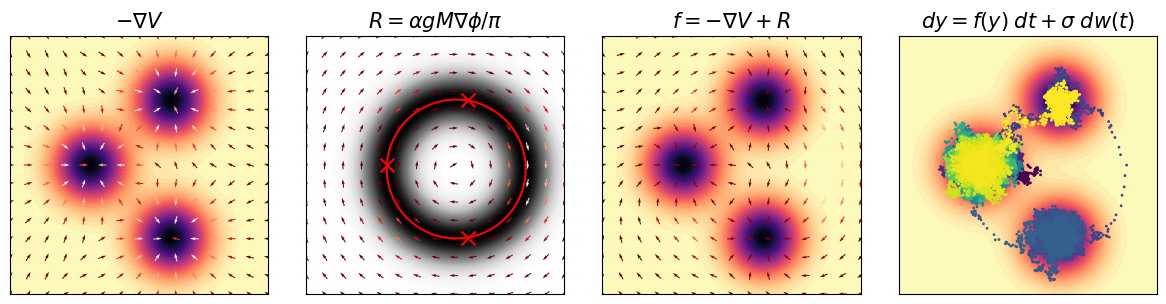

In [14]:
fig, ax = plt.subplots(1,4)
fig.set_size_inches(12,3)

grid_lim = 4; grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y, Z = potential_grid(V)

for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    neggrad = -grad_gaussian_potential_vectorized_torch(grid_points).cpu()

U = neggrad[:, 0].reshape(grid_res, grid_res).numpy()
V_ = neggrad[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[0].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)

ax[0].set_title(r'$-\nabla V$', fontsize = 15)

grid_res = 100
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs, ys, indexing="xy")

g_X = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        g_X[i, j] = g(x)

ax[1].contourf(X, Y, g_X, levels=50, cmap='Greys')

theta = np.linspace(0, 2*np.pi, 300)
cx = u_x + r * np.cos(theta)
cy = u_y + r * np.sin(theta)

ax[1].plot(cx, cy, color = 'red')
for i in range(mu.shape[1]):
    ax[1].scatter(mu[0,i],mu[1,i], color = 'red', marker = 'x', s = 100)

grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs, ys, indexing="xy")

grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    Rpi_vec = Rpi(grid_points).cpu()

U = Rpi_vec[:, 0].reshape(grid_res, grid_res).numpy()
V_ = Rpi_vec[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[1].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)

ax[1].set_title(r'$R = \alpha g M \nabla \phi /\pi$', fontsize = 15)

with torch.no_grad():
    f = gradV_gMc_pi_vec_torch(grid_points).cpu()

U = f[:, 0].reshape(grid_res, grid_res).numpy()
V_ = f[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[2].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)

ax[2].set_title(r'$f = -\nabla V + R$', fontsize = 15)

ds = 10
ax[3].scatter(traj[0,::ds],traj[1,::ds],c=time[::ds],cmap='viridis',s=1, rasterized = True)

ax[3].set_title(r'$dy = f(y) \; dt + \sigma \;dw(t)$', fontsize = 15)

for a in ax:
    a.set_xticks([])
    a.set_yticks([])
    
plt.tight_layout()
plt.show()

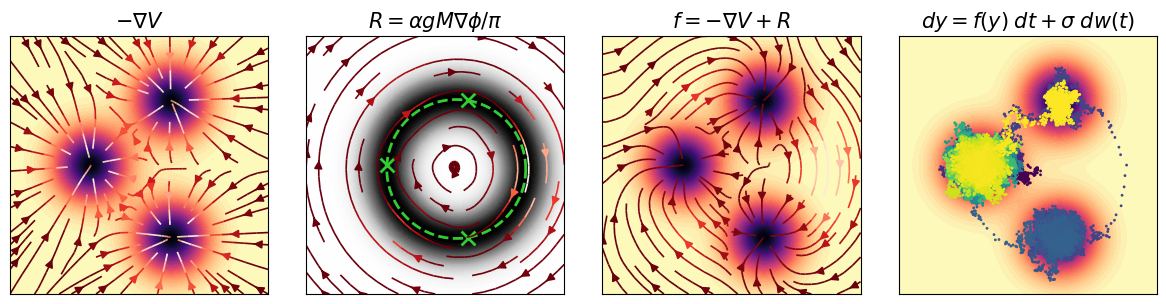

In [25]:
fig, ax = plt.subplots(1, 4)
fig.set_size_inches(12, 3)

grid_lim = 4
grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y, Z = potential_grid(V)

for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')


X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    neggrad = -grad_gaussian_potential_vectorized_torch(grid_points).cpu()

U = neggrad[:, 0].reshape(grid_res, grid_res).numpy()
V_ = neggrad[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[0].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.75, linewidth=1.2, arrowsize=1.2
)
ax[0].set_title(r'$-\nabla V$', fontsize=15)


grid_res_high = 100
xs_high = torch.linspace(-grid_lim, grid_lim, grid_res_high)
ys_high = torch.linspace(-grid_lim, grid_lim, grid_res_high)
X_high, Y_high = torch.meshgrid(xs_high, ys_high, indexing="xy")

g_X = np.zeros_like(X_high)

for i in range(X_high.shape[0]):
    for j in range(X_high.shape[1]):
        x = np.array([X_high[i, j], Y_high[i, j]])
        g_X[i, j] = g(x)

ax[1].contourf(X_high, Y_high, g_X, levels=50, cmap='Greys')

theta = np.linspace(0, 2*np.pi, 300)
cx = u_x + r * np.cos(theta)
cy = u_y + r * np.sin(theta)

ax[1].plot(cx, cy, color='limegreen', linestyle = 'dashed', linewidth = 2)
for i in range(mu.shape[1]):
    ax[1].scatter(mu[0, i], mu[1, i], color='limegreen', marker='x', s=100, linewidth = 2)

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    Rpi_vec = Rpi(grid_points).cpu()

U = Rpi_vec[:, 0].reshape(grid_res, grid_res).numpy()
V_ = Rpi_vec[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[1].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.5, linewidth=1.2, arrowsize=1.2
)
ax[1].set_title(r'$R = \alpha g M \nabla \phi /\pi$', fontsize=15)


with torch.no_grad():
    f = gradV_gMc_pi_vec_torch(grid_points).cpu()

U = f[:, 0].reshape(grid_res, grid_res).numpy()
V_ = f[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[2].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.75, linewidth=1.2, arrowsize=1.2
)
ax[2].set_title(r'$f = -\nabla V + R$', fontsize=15)


ds = 10
ax[3].scatter(
    traj[0, ::ds], traj[1, ::ds], 
    c=time[::ds], cmap='viridis', 
    s=1, rasterized=True, zorder=3
)
ax[3].set_title(r'$dy = f(y) \; dt + \sigma \;dw(t)$', fontsize=15)


for a in ax:
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

In [26]:
xmin = -5; xmax = 5
ymin = -5; ymax = 5

def potential_grid(V, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 500):
    x1 = np.linspace(xmin, xmax, no)
    y1 = np.linspace(ymin, ymax, no)
    X, Y = np.meshgrid(x1, y1)
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            Z[i, j] = V(x)
    return X, Y, Z

mu = np.array([
    [2,3],
    [3,-2],
    [-2,-3],
    [-1.5,1.5]
]).T

sigma = 0.75*np.ones(mu.shape[1])
A = 0.25*np.ones(mu.shape[1])

nu = 0.225

points = mu.T
points_closed = np.vstack([points, points[0]])
distance = np.cumsum(np.sqrt(np.sum(np.diff(points_closed, axis=0)**2, axis=1)))
t = np.insert(distance, 0, 0)

spline_x = CubicSpline(t, points_closed[:, 0], bc_type='periodic')
spline_y = CubicSpline(t, points_closed[:, 1], bc_type='periodic')

t_fine = np.linspace(t.min(), t.max(), 500)
x_spline = spline_x(t_fine)
y_spline = spline_y(t_fine)
spline_points = np.vstack([x_spline, y_spline]).T

spline_path = Path(spline_points)

def calculate_signed_distance(px, py):
    distances = np.sqrt((px - x_spline)**2 + (py - y_spline)**2)
    min_dist = np.min(distances)
    
    is_inside = spline_path.contains_point((px, py))
    sign = -1 if is_inside else 1
    
    return min_dist * sign

xi = 0.6

def g(p):
    x,y = p
    d = np.abs(calculate_signed_distance(x,y))
    return np.exp(-((d)**2)/(2*xi**2))

x_grid = np.linspace(-10, 10, 100)
y_grid = np.linspace(-10, 10, 100)
Xc, Yc = np.meshgrid(x_grid, y_grid)

vectorized_dist = np.vectorize(calculate_signed_distance)
PHI = vectorized_dist(Xc, Yc)

dPHI_dy, dPHI_dx = np.gradient(PHI)

U = dPHI_dy
V_ = -dPHI_dx

interp_U = RectBivariateSpline(y_grid, x_grid, U)
interp_V = RectBivariateSpline(y_grid, x_grid, V_)

def vector_field_interpolated(p):
    x, y = p
    u = interp_U(y, x).item()
    v = interp_V(y, x).item()
    return np.array([u, v])

alpha = 2.5

def gradV_gRSpline_pi(x):
    f = h.grad_gaussian_potential(x,mu,A,sigma)
    return -f + alpha*g(x)*vector_field_interpolated(x)/piZ(x)

def V(x):
    return h.gaussian_potential(x,mu,A,sigma)

def gradV(x):
    return h.grad_gaussian_potential(x,mu,A,sigma)

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

mu_np = mu.T.copy() 
mu_t = torch.from_numpy(mu_np).to(device=device, dtype=torch.float32)   # (K,2)
A_t = torch.from_numpy(A.astype(np.float32)).to(device=device)          # (K,)
sigma_t = torch.from_numpy(sigma.astype(np.float32)).to(device=device)  # (K,)

xi_t = float(xi)
M_t = torch.from_numpy(M.astype(np.float32)).to(device=device)       # (2,2)
alpha_t = float(alpha)
nu_t = float(nu)

def gaussian_potential_vectorized_torch(x):
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
   
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)   # (B, K, 2)
    sq = (diff * diff).sum(dim=2)               # (B, K)
    denom = 2.0 * (sigma_t ** 2)                # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))
    V = -(A_t.unsqueeze(0) * exp_term).sum(dim=1)   # (B,)
    if is_1d:
        return V[0]
    return V  # (B,)

def grad_gaussian_potential_vectorized_torch(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)        # (B, K, 2)
    sq = (diff * diff).sum(dim=2)                    # (B, K)
    denom = 2.0 * (sigma_t ** 2)                     # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))  # (B,K)
    factor = (A_t / (sigma_t ** 2)).unsqueeze(0) * exp_term   # (B,K)
    grad =  (factor.unsqueeze(2) * diff).sum(dim=1)   # (B,2)
    if is_1d:
        return grad[0]
    return grad  # (B,2)


def _ensure_points_tensor(points):
    if points.dim() == 1 and points.numel() == 2:
        pts = points.unsqueeze(0)  # (1,2)
        orig_shape = ()
    elif points.dim() == 2 and points.size(1) == 2:
        pts = points  # (B,2)
        orig_shape = (points.size(0),)
    elif points.dim() == 3 and points.size(2) == 2:
        H, W = points.shape[0], points.shape[1]
        pts = points.view(-1, 2)  # (H*W, 2)
        orig_shape = (H, W)
    else:
        raise ValueError("points must have shape (2,), (B,2) or (H,W,2)")
    return pts, orig_shape


def _reshape_output(out_flat, orig_shape):
    if orig_shape == ():
        return out_flat[0]
    elif len(orig_shape) == 1:
        return out_flat
    else:
        return out_flat.view(orig_shape)

poly_x = torch.tensor(x_spline, dtype=torch.float32)
poly_y = torch.tensor(y_spline, dtype=torch.float32)

def signed_distance_torch(points, poly_x, poly_y, spline_path=spline_path):
    
    device = poly_x.device
    dtype = poly_x.dtype

    pts, orig_shape = _ensure_points_tensor(points)
    pts = pts.to(device=device, dtype=dtype)  # (P,2)
    P = pts.size(0)

    vx = poly_x.view(1, -1)  # (1, M)
    vy = poly_y.view(1, -1)  # (1, M)

    dx = pts[:, 0].unsqueeze(1) - vx    # (P, M)
    dy = pts[:, 1].unsqueeze(1) - vy    # (P, M)
    d2 = dx * dx + dy * dy             # (P, M)
    min_d2, _ = torch.min(d2, dim=1)   # (P,)
    min_dist = torch.sqrt(min_d2 + 1e-20)  # (P,)

    if spline_path is not None:
        import numpy as np
        pts_cpu = pts.detach().cpu().numpy()  # (P,2)
        inside_mask = spline_path.contains_points(pts_cpu) 
        sign = torch.ones_like(min_dist, device=device, dtype=dtype)
        sign[torch.from_numpy(inside_mask).to(device=device)] = -1.0
    else:
        M = poly_x.numel()
        xi = poly_x.view(1, M)  # (1,M)
        yi = poly_y.view(1, M)
        xj = poly_x.roll(-1).view(1, M)
        yj = poly_y.roll(-1).view(1, M)

        px = pts[:, 0].unsqueeze(1)  # (P,1)
        py = pts[:, 1].unsqueeze(1)  # (P,1)

        yi_gt_py = (yi > py)      
        yj_gt_py = (yj > py)
        cond1 = yi_gt_py != yj_gt_py  

        denom = (yj - yi) 
        denom_safe = denom.clone()
        denom_safe[denom_safe == 0] = 1e-20

        x_inter = xi + (py - yi) * (xj - xi) / denom_safe  # (P,M)

        cond2 = px < x_inter  
        crossings = (cond1 & cond2).to(torch.int32).sum(dim=1)  # (P,)
        inside_mask = (crossings % 2 == 1)  # boolean

        sign = torch.ones_like(min_dist, device=device, dtype=dtype)
        sign[inside_mask] = -1.0

    signed = min_dist * sign
    return _reshape_output(signed, orig_shape)


def g_torch(points, poly_x, poly_y, xi, spline_path=spline_path):

    pts, orig_shape = _ensure_points_tensor(points)
    device = pts.device
    dtype = pts.dtype
    xi = torch.as_tensor(xi, device=device, dtype=dtype)

    signed = signed_distance_torch(pts, poly_x.to(device=device, dtype=dtype),
                                   poly_y.to(device=device, dtype=dtype),
                                   spline_path=spline_path)  # returns (P,) or reshaped depending
    if isinstance(signed, torch.Tensor) and signed.dim() > 1:
        signed = signed.view(-1)

    d = signed.abs()
    exponent = - (d * d) / (2.0 * (xi * xi + 1e-20))
    out = torch.exp(exponent)

    return _reshape_output(out, orig_shape)


def piZ_vec_torch(x):

    V = gaussian_potential_vectorized_torch(x)  # (B,)
    piz = torch.exp(-2.0 * V / (nu_t**2))
    return piz


def compute_phi_from_signed_distance_torch(x_grid, y_grid, poly_x, poly_y, spline_path=None):
    device = x_grid.device
    dtype = x_grid.dtype
    H, W = y_grid.numel(), x_grid.numel()

    X, Y = torch.meshgrid(y_grid, x_grid, indexing="xy")  # (H,W)
    pts = torch.stack([X, Y], dim=-1).to(device=device, dtype=dtype)  # (H,W,2)

    PHI = signed_distance_torch(pts, poly_x, poly_y, spline_path=spline_path)  # (H,W)
    return PHI


def make_field_from_phi(PHI_tensor, x_grid, y_grid):

    assert PHI_tensor.dim() == 2, "PHI must be (H,W)"
    H, W = PHI_tensor.shape
    device = PHI_tensor.device
    dtype = PHI_tensor.dtype

    phi = PHI_tensor.unsqueeze(0).unsqueeze(0)  # (1,1,H,W)

    if W > 1:
        dx = float((x_grid[-1] - x_grid[0]) / (W - 1))
    else:
        dx = 1.0
    if H > 1:
        dy = float((y_grid[-1] - y_grid[0]) / (H - 1))
    else:
        dy = 1.0

    phi_pad = F.pad(phi, (1, 1, 1, 1), mode='replicate')  # (1,1,H+2,W+2)

    dphi_dx = (phi_pad[..., 1:-1, 2:] - phi_pad[..., 1:-1, 0:-2]) / (2.0 * dx)
    dphi_dy = (phi_pad[..., 2:, 1:-1] - phi_pad[..., 0:-2, 1:-1]) / (2.0 * dy)

    assert dphi_dx.shape == (1,1,H,W), f"dphi_dx shape {dphi_dx.shape}"
    assert dphi_dy.shape == (1,1,H,W), f"dphi_dy shape {dphi_dy.shape}"

    U = dphi_dy  # (1,1,H,W)
    V = -dphi_dx

    F_field = torch.cat([U, V], dim=1)  # (1,2,H,W)
    return F_field


def sample_nc_vector_field_torch(points, F_field, x_grid, y_grid, align_corners=True):
    device = F_field.device
    dtype = F_field.dtype

    x_min, x_max = float(x_grid[0].item()), float(x_grid[-1].item())
    y_min, y_max = float(y_grid[0].item()), float(y_grid[-1].item())

    def normalize_xy(xy):
        x = (xy[..., 0] - x_min) / (x_max - x_min) * 2.0 - 1.0
        y = (xy[..., 1] - y_min) / (y_max - y_min) * 2.0 - 1.0
        return torch.stack([x, y], dim=-1)

    if points.dim() == 1 and points.numel() == 2:
        pts = points.unsqueeze(0)  # (1,2)
        orig_shape = ()
    elif points.dim() == 2 and points.size(1) == 2:
        pts = points       # (B,2)
        orig_shape = (points.size(0),)
    elif points.dim() == 3 and points.size(2) == 2:
        Hq, Wq = points.shape[0], points.shape[1]
        pts = points.view(-1, 2)  # (Hq*Wq, 2)
        orig_shape = (Hq, Wq)
    else:
        raise ValueError("points must be (2,), (B,2) or (Hq,Wq,2)")

    pts = pts.to(device=device, dtype=dtype)
    grid_coords = normalize_xy(pts)  # (P,2)

    P = grid_coords.shape[0]
    grid = grid_coords.view(1, 1, P, 2)  # (1,1,P,2)

    sampled = F.grid_sample(F_field, grid, mode='bicubic', padding_mode='border', align_corners=align_corners)
    sampled = sampled.squeeze(2).squeeze(0).permute(1,0) 

    if orig_shape == ():
        return sampled[0]            # (2,)
    elif len(orig_shape) == 1:
        return sampled               # (B,2)
    else:
        Hq, Wq = orig_shape
        return sampled.view(Hq, Wq, 2)

grid_lim = 5; grid_res = 200
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

PHI = compute_phi_from_signed_distance_torch(xs, ys, poly_x, poly_y)

F_field = make_field_from_phi(PHI, xs, ys)

def gradV_gMc_pi_vec_torch(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    nc = sample_nc_vector_field_torch(x, F_field, xs, ys,)
    grad_v = grad_gaussian_potential_vectorized_torch(x)   # (B,2)
    g_scalar = g_torch(x, poly_x, poly_y, xi, spline_path).unsqueeze(1)   # (B,1)
    piz = piZ_vec_torch(x).unsqueeze(1)      # (B,1)     # (B,1)
    piz_clamped = torch.clamp(piz, min=1e-4)  
    out = -grad_v + g_scalar * (alpha_t * nc) / piz
    if is_1d:
        return out[0]
    return out  # (B,2)

def Rpi(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    nc = sample_nc_vector_field_torch(x, F_field, xs, ys,)
    g_scalar = g_torch(x, poly_x, poly_y, xi, spline_path).unsqueeze(1)   # (B,1)
    piz = piZ_vec_torch(x).unsqueeze(1)    
    piz_clamped = torch.clamp(piz, min=1e-4)
    out = g_scalar * (alpha_t * nc) / piz
    if is_1d:
        return out[0]
    return out  # (B,2)

In [27]:
X0 = np.array([0,0])
T_t = 5000; dt = 0.005
time = np.linspace(0,T_t,int(T_t/dt))

traj = simulate_process_EM(gradV_gMc_pi,X0,T_t,dt,nu)

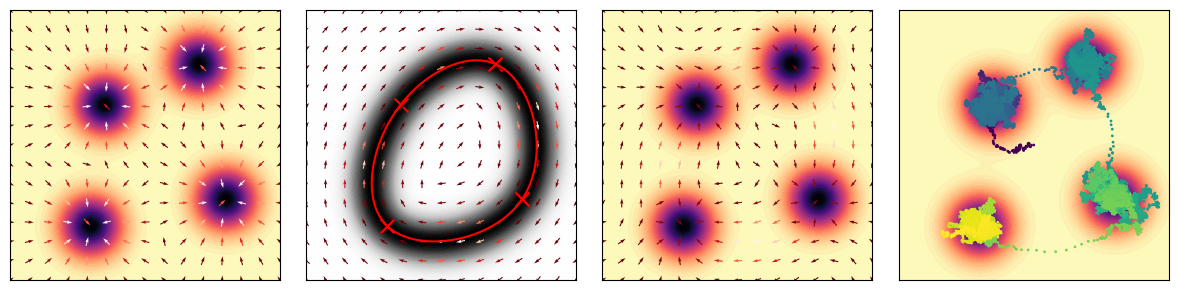

In [38]:
fig, ax = plt.subplots(1,4)
fig.set_size_inches(12,3)

grid_lim = 5; grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y, Z = potential_grid(V)

for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    neggrad = -grad_gaussian_potential_vectorized_torch(grid_points).cpu()

U = neggrad[:, 0].reshape(grid_res, grid_res).numpy()
V_ = neggrad[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[0].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)

grid_res = 100
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs, ys, indexing="xy")
g_X = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        g_X[i, j] = g(x)
        
ax[1].contourf(X, Y, g_X, levels=50, cmap='Greys')
ax[1].plot(x_spline, y_spline, 'r-')
for i in range(mu.shape[1]):
    ax[1].scatter(mu[0,i],mu[1,i], color = 'red', marker = 'x', s = 100)

grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs, ys, indexing="xy")

grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    Rpi_vec = Rpi(grid_points).cpu()

U = Rpi_vec[:, 0].reshape(grid_res, grid_res).numpy()
V_ = Rpi_vec[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[1].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)


with torch.no_grad():
    f = gradV_gMc_pi_vec_torch(grid_points).cpu()

U = f[:, 0].reshape(grid_res, grid_res).numpy()
V_ = f[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[2].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)


ds = 10
ax[3].scatter(traj1[0,::ds],traj1[1,::ds],c=time1[::ds],cmap='viridis',s=1, rasterized = True)

for a in ax:
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

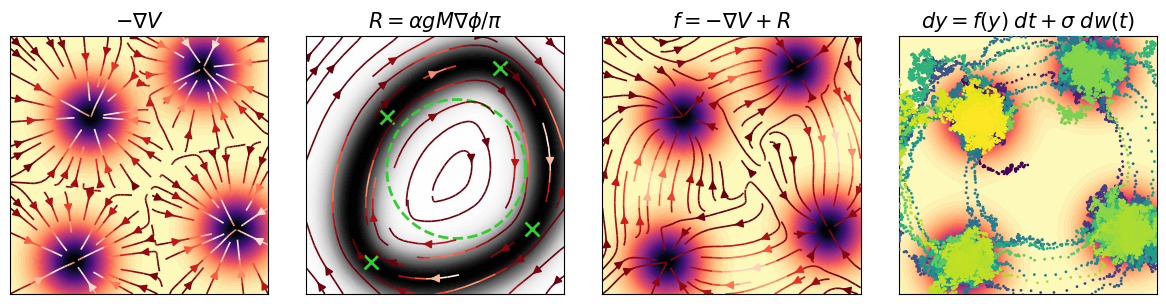

In [39]:
fig, ax = plt.subplots(1, 4)
fig.set_size_inches(12, 3)

grid_lim = 4
grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y, Z = potential_grid(V)

for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')


X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    neggrad = -grad_gaussian_potential_vectorized_torch(grid_points).cpu()

U = neggrad[:, 0].reshape(grid_res, grid_res).numpy()
V_ = neggrad[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[0].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.75, linewidth=1.2, arrowsize=1.2
)
ax[0].set_title(r'$-\nabla V$', fontsize=15)


grid_res_high = 100
xs_high = torch.linspace(-grid_lim, grid_lim, grid_res_high)
ys_high = torch.linspace(-grid_lim, grid_lim, grid_res_high)
X_high, Y_high = torch.meshgrid(xs_high, ys_high, indexing="xy")

g_X = np.zeros_like(X_high)

for i in range(X_high.shape[0]):
    for j in range(X_high.shape[1]):
        x = np.array([X_high[i, j], Y_high[i, j]])
        g_X[i, j] = g(x)

ax[1].contourf(X_high, Y_high, g_X, levels=50, cmap='Greys')

theta = np.linspace(0, 2*np.pi, 300)
cx = u_x + r * np.cos(theta)
cy = u_y + r * np.sin(theta)

ax[1].plot(cx, cy, color='limegreen', linestyle = 'dashed', linewidth = 2)
for i in range(mu.shape[1]):
    ax[1].scatter(mu[0, i], mu[1, i], color='limegreen', marker='x', s=100, linewidth = 2)

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    Rpi_vec = Rpi(grid_points).cpu()

U = Rpi_vec[:, 0].reshape(grid_res, grid_res).numpy()
V_ = Rpi_vec[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[1].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.5, linewidth=1.2, arrowsize=1.2
)
ax[1].set_title(r'$R = \alpha g M \nabla \phi /\pi$', fontsize=15)


with torch.no_grad():
    f = gradV_gMc_pi_vec_torch(grid_points).cpu()

U = f[:, 0].reshape(grid_res, grid_res).numpy()
V_ = f[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[2].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.75, linewidth=1.2, arrowsize=1.2
)
ax[2].set_title(r'$f = -\nabla V + R$', fontsize=15)


ds = 10
ax[3].scatter(
    traj[0, ::ds], traj[1, ::ds], 
    c=time[::ds], cmap='viridis', 
    s=1, rasterized=True, zorder=3
)
ax[3].set_title(r'$dy = f(y) \; dt + \sigma \;dw(t)$', fontsize=15)


for a in ax:
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(1,4)
fig.set_size_inches(12,3)

grid_lim = 5; grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y, Z = potential_grid(V)

for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    neggrad = -grad_gaussian_potential_vectorized_torch(grid_points).cpu()

U = neggrad[:, 0].reshape(grid_res, grid_res).numpy()
V_ = neggrad[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[0].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)

grid_res = 100
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs, ys, indexing="xy")
g_X = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        g_X[i, j] = g(x)
        
ax[1].contourf(X, Y, g_X, levels=50, cmap='Greys')
ax[1].plot(x_spline, y_spline, 'r-')
for i in range(mu.shape[1]):
    ax[1].scatter(mu[0,i],mu[1,i], color = 'red', marker = 'x', s = 100)

grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs, ys, indexing="xy")

grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    Rpi_vec = Rpi(grid_points).cpu()

U = Rpi_vec[:, 0].reshape(grid_res, grid_res).numpy()
V_ = Rpi_vec[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[1].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)


with torch.no_grad():
    f = gradV_gMc_pi_vec_torch(grid_points).cpu()

U = f[:, 0].reshape(grid_res, grid_res).numpy()
V_ = f[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[2].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)


ds = 10
ax[3].scatter(traj1[0,::ds],traj1[1,::ds],c=time1[::ds],cmap='viridis',s=1, rasterized = True)

for a in ax:
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

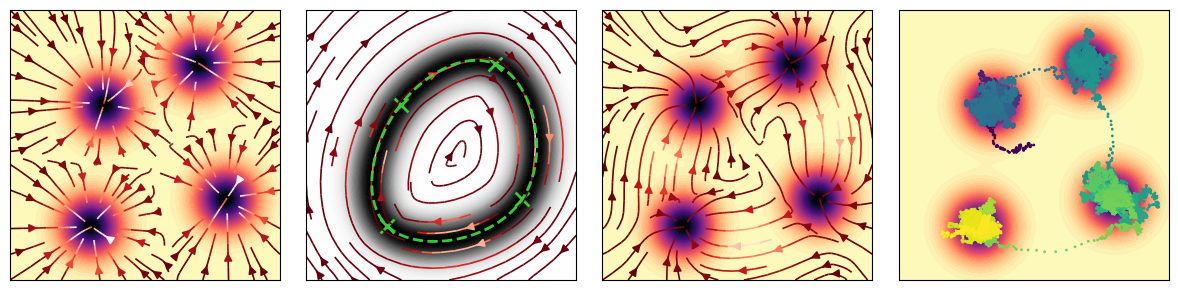

In [43]:
fig, ax = plt.subplots(1, 4)
fig.set_size_inches(12, 3)

grid_lim = 5
grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y, Z = potential_grid(V)

for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    neggrad = -grad_gaussian_potential_vectorized_torch(grid_points).cpu()

U = neggrad[:, 0].reshape(grid_res, grid_res).numpy()
V_ = neggrad[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[0].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.75, linewidth=1.2, arrowsize=1.2
)


grid_res_high = 100
xs_high = torch.linspace(-grid_lim, grid_lim, grid_res_high)
ys_high = torch.linspace(-grid_lim, grid_lim, grid_res_high)
X_high, Y_high = torch.meshgrid(xs_high, ys_high, indexing="xy")
g_X = np.zeros_like(X_high)

for i in range(X_high.shape[0]):
    for j in range(X_high.shape[1]):
        x = np.array([X_high[i, j], Y_high[i, j]])
        g_X[i, j] = g(x)
        
ax[1].contourf(X_high, Y_high, g_X, levels=50, cmap='Greys')
ax[1].plot(x_spline, y_spline, color = 'limegreen', linestyle = 'dashed', linewidth = 2, zorder = 10)
for i in range(mu.shape[1]):
    ax[1].scatter(mu[0, i], mu[1, i], color='limegreen', marker='x', s=100, linewidth = 2)

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    Rpi_vec = Rpi(grid_points).cpu()

U = Rpi_vec[:, 0].reshape(grid_res, grid_res).numpy()
V_ = Rpi_vec[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[1].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.6, linewidth=1.2, arrowsize=1.2
)

with torch.no_grad():
    f = gradV_gMc_pi_vec_torch(grid_points).cpu()

U = f[:, 0].reshape(grid_res, grid_res).numpy()
V_ = f[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[2].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.75, linewidth=1.2, arrowsize=1.2
)


ds = 10
ax[3].scatter(
    traj1[0, ::ds], traj1[1, ::ds], 
    c=time1[::ds], cmap='viridis', 
    s=1, rasterized=True, zorder=3
)

# Formatting
for a in ax:
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_7080/936893801.py:10: UserWarning: linewidths is ignored by contourf
  c = ax[0].contourf(X, Y, Z, levels=50, cmap='magma',edgecolor='none',linewidths=0)
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_7080/936893801.py:10: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  c = ax[0].contourf(X, Y, Z, levels=50, cmap='magma',edgecolor='none',linewidths=0)
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_7080/936893801.py:35: UserWarning: linewidths is ignored by contourf
  c = ax[1].contourf(X, Y, g_X, levels=50, cmap='Greys',linewidths=0 ,color = "face")
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_7080/936893801.py:35: UserWarning: The following kwargs were not used by contour: 'color'
  c = ax[1].contourf(X, Y, g_X, levels=50, cmap='Greys',linewidths=0 ,color = "face")


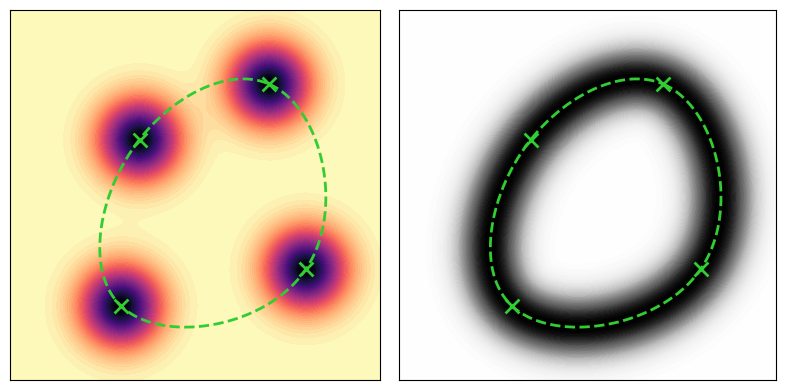

In [45]:
fig, ax = plt.subplots(1,2)
fig.set_size_inches(8,4)

grid_lim = 5; grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y, Z = potential_grid(V)

c = ax[0].contourf(X, Y, Z, levels=50, cmap='magma',edgecolor='none',linewidths=0)
c.set_edgecolor("face")
ax[0].set_xlim(-grid_lim, grid_lim)
ax[0].set_ylim(-grid_lim, grid_lim)
ax[0].set_aspect('equal')

for a in ax:
    a.set_xticks([])
    a.set_yticks([])

ax[0].plot(x_spline, y_spline, color = 'limegreen', linewidth = 2, linestyle = 'dashed')
for i in range(mu.shape[1]):
    ax[0].scatter(mu[0,i],mu[1,i], color = 'limegreen', marker = 'x', s = 100, linewidth = 2)

grid_res = 100
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs, ys, indexing="xy")
g_X = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        g_X[i, j] = g(x)
        
c = ax[1].contourf(X, Y, g_X, levels=50, cmap='Greys',linewidths=0 ,color = "face")
c.set_edgecolor("face")
ax[1].plot(x_spline, y_spline, color = 'limegreen', linewidth = 2, linestyle = 'dashed')
for i in range(mu.shape[1]):
    ax[1].scatter(mu[0,i],mu[1,i], color = 'limegreen', marker = 'x', s = 100, linewidth = 2)

plt.tight_layout()
plt.show()

In [50]:
xmin = -8; xmax = 8
ymin = -8; ymax = 8

mu = np.array([
    [3.5,4],
    [0,0],
    [3,-4],
    [-3,-4],
    [-3.5,4]
]).T

sigma = 0.6*np.ones(mu.shape[1])
A = 0.25*np.ones(mu.shape[1])

def V(x):
    return h.gaussian_potential(x,mu,A,sigma)

def gradV(x):
    return h.grad_gaussian_potential(x,mu,A,sigma)

nu = 0.225

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

points = mu.T
points_closed = np.vstack([points, points[0]])
distance = np.cumsum(np.sqrt(np.sum(np.diff(points_closed, axis=0)**2, axis=1)))
t = np.insert(distance, 0, 0)

spline_x = CubicSpline(t, points_closed[:, 0], bc_type='periodic')
spline_y = CubicSpline(t, points_closed[:, 1], bc_type='periodic')

t_fine = np.linspace(t.min(), t.max(), 500)
x_spline = spline_x(t_fine)
y_spline = spline_y(t_fine)
spline_points = np.vstack([x_spline, y_spline]).T

spline_path = Path(spline_points)

def calculate_signed_distance(px, py):
    distances = np.sqrt((px - x_spline)**2 + (py - y_spline)**2)
    min_dist = np.min(distances)
    
    is_inside = spline_path.contains_point((px, py))
    sign = -1 if is_inside else 1
    
    return min_dist * sign

xi = 0.6

def g(p):
    x,y = p
    d = np.abs(calculate_signed_distance(x,y))
    return np.exp(-((d)**2)/(2*xi**2))

x1 = np.linspace(xmin, xmax, 200)
y1 = np.linspace(ymin, ymax, 200)
X, Y = np.meshgrid(x1, y1)

Z = np.zeros_like(X)
g_X = np.zeros_like(X)


for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        Z[i, j] = V(x)
        g_X[i, j] = g(x)


x_grid = np.linspace(-10, 10, 100)
y_grid = np.linspace(-10, 10, 100)
Xc, Yc = np.meshgrid(x_grid, y_grid)

vectorized_dist = np.vectorize(calculate_signed_distance)
PHI = vectorized_dist(Xc, Yc)

dPHI_dy, dPHI_dx = np.gradient(PHI)

U = dPHI_dy
V_ = -dPHI_dx

interp_U = RectBivariateSpline(y_grid, x_grid, U)
interp_V = RectBivariateSpline(y_grid, x_grid, V_)

def vector_field_interpolated(p):
    x, y = p
    u = interp_U(y, x).item()
    v = interp_V(y, x).item()
    return np.array([u, v])

alpha = 2.5

def gradV_gRSpline_pi(x):
    f = h.grad_gaussian_potential(x,mu,A,sigma)
    return -f + alpha*g(x)*vector_field_interpolated(x)/piZ(x)

In [51]:
mu_np = mu.T.copy() 
mu_t = torch.from_numpy(mu_np).to(device=device, dtype=torch.float32)   # (K,2)
A_t = torch.from_numpy(A.astype(np.float32)).to(device=device)          # (K,)
sigma_t = torch.from_numpy(sigma.astype(np.float32)).to(device=device)  # (K,)

xi_t = float(xi)
M_t = torch.from_numpy(M.astype(np.float32)).to(device=device)       # (2,2)
alpha_t = float(alpha)
nu_t = float(nu)

def gaussian_potential_vectorized_torch(x):
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
   
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)   # (B, K, 2)
    sq = (diff * diff).sum(dim=2)               # (B, K)
    denom = 2.0 * (sigma_t ** 2)                # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))
    V = -(A_t.unsqueeze(0) * exp_term).sum(dim=1)   # (B,)
    if is_1d:
        return V[0]
    return V  # (B,)

def grad_gaussian_potential_vectorized_torch(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)        # (B, K, 2)
    sq = (diff * diff).sum(dim=2)                    # (B, K)
    denom = 2.0 * (sigma_t ** 2)                     # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))  # (B,K)
    factor = (A_t / (sigma_t ** 2)).unsqueeze(0) * exp_term   # (B,K)
    grad =  (factor.unsqueeze(2) * diff).sum(dim=1)   # (B,2)
    if is_1d:
        return grad[0]
    return grad  # (B,2)


def _ensure_points_tensor(points):
    if points.dim() == 1 and points.numel() == 2:
        pts = points.unsqueeze(0)  # (1,2)
        orig_shape = ()
    elif points.dim() == 2 and points.size(1) == 2:
        pts = points  # (B,2)
        orig_shape = (points.size(0),)
    elif points.dim() == 3 and points.size(2) == 2:
        H, W = points.shape[0], points.shape[1]
        pts = points.view(-1, 2)  # (H*W, 2)
        orig_shape = (H, W)
    else:
        raise ValueError("points must have shape (2,), (B,2) or (H,W,2)")
    return pts, orig_shape


def _reshape_output(out_flat, orig_shape):
    if orig_shape == ():
        return out_flat[0]
    elif len(orig_shape) == 1:
        return out_flat
    else:
        return out_flat.view(orig_shape)

poly_x = torch.tensor(x_spline, dtype=torch.float32)
poly_y = torch.tensor(y_spline, dtype=torch.float32)

def signed_distance_torch(points, poly_x, poly_y, spline_path=spline_path):
    
    device = poly_x.device
    dtype = poly_x.dtype

    pts, orig_shape = _ensure_points_tensor(points)
    pts = pts.to(device=device, dtype=dtype)  # (P,2)
    P = pts.size(0)

    vx = poly_x.view(1, -1)  # (1, M)
    vy = poly_y.view(1, -1)  # (1, M)

    dx = pts[:, 0].unsqueeze(1) - vx    # (P, M)
    dy = pts[:, 1].unsqueeze(1) - vy    # (P, M)
    d2 = dx * dx + dy * dy             # (P, M)
    min_d2, _ = torch.min(d2, dim=1)   # (P,)
    min_dist = torch.sqrt(min_d2 + 1e-20)  # (P,)

    if spline_path is not None:
        import numpy as np
        pts_cpu = pts.detach().cpu().numpy()  # (P,2)
        inside_mask = spline_path.contains_points(pts_cpu)  
        sign = torch.ones_like(min_dist, device=device, dtype=dtype)
        sign[torch.from_numpy(inside_mask).to(device=device)] = -1.0
    else:
        M = poly_x.numel()
        xi = poly_x.view(1, M)  # (1,M)
        yi = poly_y.view(1, M)
        xj = poly_x.roll(-1).view(1, M)
        yj = poly_y.roll(-1).view(1, M)

        px = pts[:, 0].unsqueeze(1)  # (P,1)
        py = pts[:, 1].unsqueeze(1)  # (P,1)

        yi_gt_py = (yi > py)      
        yj_gt_py = (yj > py)
        cond1 = yi_gt_py != yj_gt_py  

        denom = (yj - yi)  
        denom_safe = denom.clone()
        denom_safe[denom_safe == 0] = 1e-20

        x_inter = xi + (py - yi) * (xj - xi) / denom_safe  # (P,M)

        cond2 = px < x_inter  # (P,M) 
        crossings = (cond1 & cond2).to(torch.int32).sum(dim=1)  # (P,)
        inside_mask = (crossings % 2 == 1)  # boolean

        sign = torch.ones_like(min_dist, device=device, dtype=dtype)
        sign[inside_mask] = -1.0

    signed = min_dist * sign
    return _reshape_output(signed, orig_shape)


def g_torch(points, poly_x, poly_y, xi, spline_path=spline_path):

    pts, orig_shape = _ensure_points_tensor(points)
    device = pts.device
    dtype = pts.dtype
    xi = torch.as_tensor(xi, device=device, dtype=dtype)

    signed = signed_distance_torch(pts, poly_x.to(device=device, dtype=dtype),
                                   poly_y.to(device=device, dtype=dtype),
                                   spline_path=spline_path)  
    if isinstance(signed, torch.Tensor) and signed.dim() > 1:
        signed = signed.view(-1)

    d = signed.abs()
    exponent = - (d * d) / (2.0 * (xi * xi + 1e-20))
    out = torch.exp(exponent)

    return _reshape_output(out, orig_shape)


def piZ_vec_torch(x):

    V = gaussian_potential_vectorized_torch(x)  # (B,)
    piz = torch.exp(-2.0 * V / (nu_t**2))
    return piz


def compute_phi_from_signed_distance_torch(x_grid, y_grid, poly_x, poly_y, spline_path=None):
    device = x_grid.device
    dtype = x_grid.dtype
    H, W = y_grid.numel(), x_grid.numel()

    X, Y = torch.meshgrid(y_grid, x_grid, indexing="xy")  # (H,W)
    pts = torch.stack([X, Y], dim=-1).to(device=device, dtype=dtype)  # (H,W,2)

    PHI = signed_distance_torch(pts, poly_x, poly_y, spline_path=spline_path)  # (H,W)
    return PHI


def make_field_from_phi(PHI_tensor, x_grid, y_grid):

    assert PHI_tensor.dim() == 2, "PHI must be (H,W)"
    H, W = PHI_tensor.shape
    device = PHI_tensor.device
    dtype = PHI_tensor.dtype

    phi = PHI_tensor.unsqueeze(0).unsqueeze(0)  # (1,1,H,W)

    if W > 1:
        dx = float((x_grid[-1] - x_grid[0]) / (W - 1))
    else:
        dx = 1.0
    if H > 1:
        dy = float((y_grid[-1] - y_grid[0]) / (H - 1))
    else:
        dy = 1.0

    phi_pad = F.pad(phi, (1, 1, 1, 1), mode='replicate')  # (1,1,H+2,W+2)

    dphi_dx = (phi_pad[..., 1:-1, 2:] - phi_pad[..., 1:-1, 0:-2]) / (2.0 * dx)
    dphi_dy = (phi_pad[..., 2:, 1:-1] - phi_pad[..., 0:-2, 1:-1]) / (2.0 * dy)

    assert dphi_dx.shape == (1,1,H,W), f"dphi_dx shape {dphi_dx.shape}"
    assert dphi_dy.shape == (1,1,H,W), f"dphi_dy shape {dphi_dy.shape}"

    U = dphi_dy  # (1,1,H,W)
    V = -dphi_dx

    F_field = torch.cat([U, V], dim=1)  # (1,2,H,W)
    return F_field


def sample_nc_vector_field_torch(points, F_field, x_grid, y_grid, align_corners=True):
    device = F_field.device
    dtype = F_field.dtype

    x_min, x_max = float(x_grid[0].item()), float(x_grid[-1].item())
    y_min, y_max = float(y_grid[0].item()), float(y_grid[-1].item())

    def normalize_xy(xy):
        x = (xy[..., 0] - x_min) / (x_max - x_min) * 2.0 - 1.0
        y = (xy[..., 1] - y_min) / (y_max - y_min) * 2.0 - 1.0
        return torch.stack([x, y], dim=-1)

    if points.dim() == 1 and points.numel() == 2:
        pts = points.unsqueeze(0)  # (1,2)
        orig_shape = ()
    elif points.dim() == 2 and points.size(1) == 2:
        pts = points       # (B,2)
        orig_shape = (points.size(0),)
    elif points.dim() == 3 and points.size(2) == 2:
        Hq, Wq = points.shape[0], points.shape[1]
        pts = points.view(-1, 2)  # (Hq*Wq, 2)
        orig_shape = (Hq, Wq)
    else:
        raise ValueError("points must be (2,), (B,2) or (Hq,Wq,2)")

    pts = pts.to(device=device, dtype=dtype)
    grid_coords = normalize_xy(pts)  # (P,2)

    P = grid_coords.shape[0]
    grid = grid_coords.view(1, 1, P, 2)  # (1,1,P,2)

    sampled = F.grid_sample(F_field, grid, mode='bicubic', padding_mode='border', align_corners=align_corners)
    sampled = sampled.squeeze(2).squeeze(0).permute(1,0) 

    if orig_shape == ():
        return sampled[0]            # (2,)
    elif len(orig_shape) == 1:
        return sampled               # (B,2)
    else:
        Hq, Wq = orig_shape
        return sampled.view(Hq, Wq, 2)

grid_lim = 8; grid_res = 200
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

PHI = compute_phi_from_signed_distance_torch(xs, ys, poly_x, poly_y)

F_field = make_field_from_phi(PHI, xs, ys)

def gradV_gMc_pi_vec_torch(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    nc = sample_nc_vector_field_torch(x, F_field, xs, ys,)
    grad_v = grad_gaussian_potential_vectorized_torch(x)   # (B,2)
    g_scalar = g_torch(x, poly_x, poly_y, xi, spline_path).unsqueeze(1)   # (B,1)
    piz = piZ_vec_torch(x).unsqueeze(1)      # (B,1)     # (B,1)
    piz_clamped = torch.clamp(piz, min=1e-4)  # <- choose 1e-3 or 1e-4
    out = -grad_v + g_scalar * (alpha_t * nc) / piz
    if is_1d:
        return out[0]
    return out  # (B,2)

xmin = -8; xmax = 8
ymin = -8; ymax = 8

def potential_grid(V, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 500):
    x1 = np.linspace(xmin, xmax, no)
    y1 = np.linspace(ymin, ymax, no)
    X, Y = np.meshgrid(x1, y1)
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            Z[i, j] = V(x)
    return X, Y, Z

def Rpi(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)

    nc = sample_nc_vector_field_torch(x, F_field, xs, ys,)
    g_scalar = g_torch(x, poly_x, poly_y, xi, spline_path).unsqueeze(1)   # (B,1)
    piz = piZ_vec_torch(x).unsqueeze(1)      # (B,1)     # (B,1)
    piz_clamped = torch.clamp(piz, min=1e-4)  # <- choose 1e-3 or 1e-4
    out = g_scalar * (alpha_t * nc) / piz
    if is_1d:
        return out[0]
    return out  # (B,2)

In [52]:
X0 = np.array([0,0])
T_t = 20000; dt = 0.01
time = np.linspace(0,T_t,int(T_t/dt))

traj = simulate_process_EM(gradV_gRSpline_pi,X0,T_t,dt,nu)

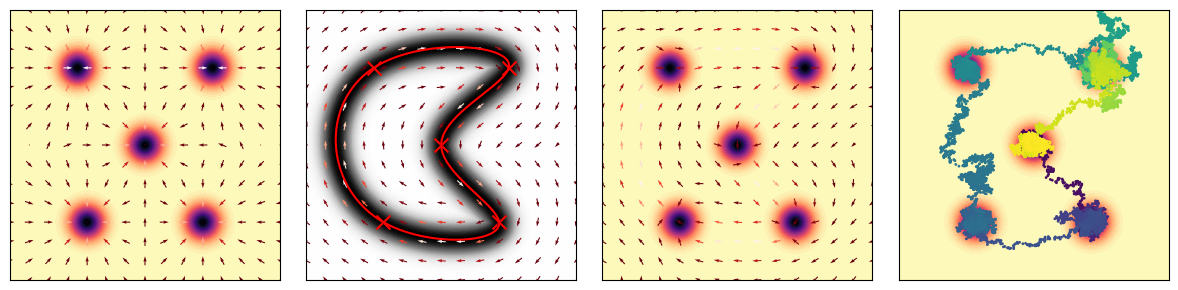

In [56]:
fig, ax = plt.subplots(1,4)
fig.set_size_inches(12,3)

grid_lim = 7; grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y, Z = potential_grid(V)

for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    neggrad = -grad_gaussian_potential_vectorized_torch(grid_points).cpu()

U = neggrad[:, 0].reshape(grid_res, grid_res).numpy()
V_ = neggrad[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[0].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)

grid_res = 100
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs, ys, indexing="xy")
g_X = np.zeros_like(X)

for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        g_X[i, j] = g(x)
        
ax[1].contourf(X, Y, g_X, levels=50, cmap='Greys')
ax[1].plot(x_spline, y_spline, 'r-')
for i in range(mu.shape[1]):
    ax[1].scatter(mu[0,i],mu[1,i], color = 'red', marker = 'x', s = 100)

grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)
X, Y = torch.meshgrid(xs, ys, indexing="xy")

grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    Rpi_vec = Rpi(grid_points).cpu()

U = Rpi_vec[:, 0].reshape(grid_res, grid_res).numpy()
V_ = Rpi_vec[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U  / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[1].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)


with torch.no_grad():
    f = gradV_gMc_pi_vec_torch(grid_points).cpu()

U = f[:, 0].reshape(grid_res, grid_res).numpy()
V_ = f[:, 1].reshape(grid_res, grid_res).numpy()

mag = np.sqrt(U**2 + V_**2)

eps = 1e-12
U_norm = U / (mag + eps)
V_norm = V_ / (mag + eps)

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

q = ax[2].quiver(
    Xn, Yn,
    U_norm, V_norm,
    mag,                
    cmap='Reds_r',
    scale=30,           
    pivot='mid'
)


ds = 10
ax[3].scatter(traj1[0,::ds],traj1[1,::ds],c=time1[::ds],cmap='viridis',s=1, rasterized = True)

for a in ax:
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.show()

In [55]:
traj1 = traj[:,:200000]
time1 = time[:200000]

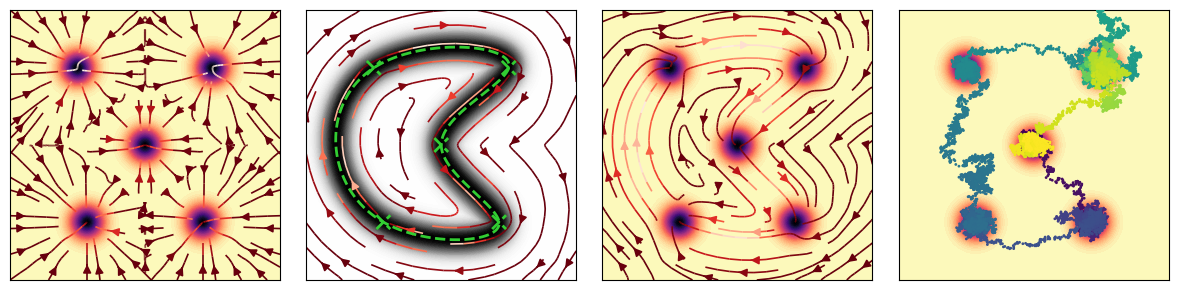

In [60]:
fig, ax = plt.subplots(1, 4)
fig.set_size_inches(12, 3)

grid_lim = 7
grid_res = 15
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

X, Y, Z = potential_grid(V)

for a in ax:
    a.contourf(X, Y, Z, levels=50, cmap='magma')
    a.set_xlim(-grid_lim, grid_lim)
    a.set_ylim(-grid_lim, grid_lim)
    a.set_aspect('equal')

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    neggrad = -grad_gaussian_potential_vectorized_torch(grid_points).cpu()

U = neggrad[:, 0].reshape(grid_res, grid_res).numpy()
V_ = neggrad[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[0].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.75, linewidth=1.2, arrowsize=1.2
)

grid_res_high = 100
xs_high = torch.linspace(-grid_lim, grid_lim, grid_res_high)
ys_high = torch.linspace(-grid_lim, grid_lim, grid_res_high)
X_high, Y_high = torch.meshgrid(xs_high, ys_high, indexing="xy")
g_X = np.zeros_like(X_high)

for i in range(X_high.shape[0]):
    for j in range(X_high.shape[1]):
        x = np.array([X_high[i, j], Y_high[i, j]])
        g_X[i, j] = g(x)
        
ax[1].contourf(X_high, Y_high, g_X, levels=50, cmap='Greys')

ax[1].plot(x_spline, y_spline, color='limegreen', linestyle='--', linewidth=2, zorder = 100)
for i in range(mu.shape[1]):
    ax[1].scatter(
        mu[0, i], mu[1, i], 
        color='limegreen', marker='x', s=100, 
        linewidths=2, linestyles='--', zorder = 100
    )

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    Rpi_vec = Rpi(grid_points).cpu()

U = Rpi_vec[:, 0].reshape(grid_res, grid_res).numpy()
V_ = Rpi_vec[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[1].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.55, linewidth=1.2, arrowsize=1.2
)


with torch.no_grad():
    f = gradV_gMc_pi_vec_torch(grid_points).cpu()

U = f[:, 0].reshape(grid_res, grid_res).numpy()
V_ = f[:, 1].reshape(grid_res, grid_res).numpy()
mag = np.sqrt(U**2 + V_**2)
Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()

ax[2].streamplot(
    Xn, Yn, U, V_, 
    color=mag, cmap='Reds_r', 
    density=0.75, linewidth=1.2, arrowsize=1.2
)


ds = 10
ax[3].scatter(
    traj1[0, ::ds], traj1[1, ::ds], 
    c=time1[::ds], cmap='viridis', 
    s=1, rasterized=True, zorder=3
)


for a in ax:
    a.set_xticks([])
    a.set_yticks([])

plt.tight_layout()
plt.savefig("attractor_cycling_5_streams.pdf", bbox_inches='tight', pad_inches=0.1, dpi=600)    
plt.show()